In [2]:
import numpy as np
import pandas as pd
import torch
from sklearn import preprocessing
import matplotlib.pyplot as plt

In [3]:
# Load the file using the path exactly as it was saved
file_path = '../data/embeddings_2026-1-10_15-24-10_2176_32768_blocks.28.mlp.l3_16384_0.pt'
data = torch.load(file_path, map_location=torch.device('cpu'))

# Extract the lists from the dictionary
ids = data["ids"]               # List of strings
# DeepPL files contains accession id without version number, so we need to erase it from our ids
ids = [item.split('.')[0] for item in ids] 
embeddings_list = data["embeddings"] # List of torch.Tensors
starts_list = data['starts']
ends_list = data['ends']

# Stack the list of tensors into one large tensor (N_samples x 4096)
embeddings_tensor = torch.stack(embeddings_list)

# Convert to Numpy array
loaded_embeds = embeddings_tensor.detach().cpu().numpy()
loaded_ids = np.array(ids)

# Sanity checks
assert len(ids) == loaded_embeds.shape[0] == len(starts_list) == len(ends_list)

print("IDs array shape:", loaded_ids.shape)
print("Embeddings array shape:", loaded_embeds.shape) 

df = pd.DataFrame(
    data=loaded_embeds[:,:],
    index=loaded_ids[:],
    columns=[[f"feature_{i}" for i in range(len(loaded_embeds[0]))]]
) 


# Take a look
df.head()

IDs array shape: (10427,)
Embeddings array shape: (10427, 4096)


,feature_0,feature_1,feature_2,feature_3,feature_4,feature_5,feature_6,feature_7,feature_8,feature_9,...,feature_4086,feature_4087,feature_4088,feature_4089,feature_4090,feature_4091,feature_4092,feature_4093,feature_4094,feature_4095
NC_012663,47.00,-93.0,-69.5,96.5,102.0,-44.00,-122.0,44.00,-75.0,-268.0,...,-41.75,36.000,-59.00,-62.75,-59.5,82.0,80.5,-116.5,-74.50,0.75000
NC_012663,46.00,-93.0,-75.0,94.5,97.5,-42.00,-120.0,41.75,-81.5,-260.0,...,-41.00,32.250,-61.00,-62.50,-61.5,78.0,80.5,-112.5,-78.50,-6.78125
NC_012663,46.25,-94.0,-75.5,92.5,102.0,-39.00,-116.5,40.25,-84.0,-249.0,...,-41.50,30.125,-62.50,-65.50,-66.0,75.5,85.0,-110.5,-70.00,-14.00000
NC_012663,50.25,-98.0,-63.5,91.5,119.0,-37.00,-114.0,45.00,-74.0,-246.0,...,-46.00,35.250,-63.25,-73.00,-72.0,87.0,103.5,-116.0,-42.50,-10.25000
NC_025467,58.25,-94.0,-83.5,96.5,103.0,-48.75,-115.5,43.75,-69.0,-276.0,...,-51.00,38.000,-58.00,-56.75,-55.5,100.0,83.0,-121.0,-23.75,-24.12500


In [4]:
print(len(loaded_ids)) # Total number of ids
print(len(set(loaded_ids))) # Unique ids

10427
2176


In [5]:
# Path to the Excel file containing lifecycle information
excel_file_path = "../data/journal.pcbi.1012525.s001.xlsx"
# Training
sheet_names = pd.ExcelFile(excel_file_path).sheet_names
# Training dataset
training = pd.read_excel(excel_file_path, sheet_name=sheet_names[0])
# Test dataset
test = pd.read_excel(excel_file_path, sheet_name=sheet_names[1])

# Create a dictionary mapping Accession ID -> Corrected Lifecycle
lifecycle_map = {}
all_metadata = pd.concat([training, test])

# Standardize lifecycle labels and populate the map
for _, row in all_metadata.iterrows():
    acc = row['Accession number']
    raw_life = row['Lifecycle']
    clean_life = "lysogenic" if str(raw_life).strip().lower() in ["lysogneic", "lysogenic"] else "lytic"
    lifecycle_map[acc] = clean_life

# Create aligned list
aligned_lifecycles = []
for accession in df.index:
    if accession in lifecycle_map:
        aligned_lifecycles.append(lifecycle_map[accession])
    else:
        # Warning only once per missing ID to avoid clutter
        print(f"Warning: Accession {accession} not found. Defaulting to lytic.")
        aligned_lifecycles.append("lytic") 

aligned_lifecycles = np.array(aligned_lifecycles)
print(f"Aligned labels length: {len(aligned_lifecycles)}")

Aligned labels length: 10427


In [6]:
# Set global random state for following models
RANDOM_STATE = 0

train_ids = set(training['Accession number'].astype(str).str.strip())
test_ids = set(test['Accession number'].astype(str).str.strip())

# Prepare feature and labels
train_indices = []
test_indices = []
y_train = []
y_test = []

for i, accession in enumerate(df.index):
    label = lifecycle_map.get(accession, "lytic")
    
    if accession in train_ids:
        train_indices.append(i)
        y_train.append(label)
    elif accession in test_ids:
        test_indices.append(i)
        y_test.append(label)


X_train = df.iloc[train_indices]
X_test = df.iloc[test_indices]
y_train = np.array(y_train)
y_test = np.array(y_test)

# Normalize data (row-wise)
normalizer = preprocessing.Normalizer()
X_train = normalizer.transform(X_train)
X_test = normalizer.transform(X_test)

print(f"Data Split Loaded: {len(X_train)} Train, {len(X_test)} Test")


Data Split Loaded: 8613 Train, 1814 Test


In [7]:
from sklearn.metrics import (confusion_matrix, accuracy_score, f1_score, 
                             matthews_corrcoef, make_scorer)

# We tell the tuner: "Find the threshold that maximizes F1 score for 'lysogenic'"
f1_scorer = make_scorer(f1_score, pos_label="lysogenic")

# Define function to print metrics for each model
def compute_and_print_metrics(model_name, y_true, y_pred, pos_label="lysogenic"):
    acc = accuracy_score(y_true, y_pred)
    f1 = f1_score(y_true, y_pred, pos_label=pos_label)
    mcc = matthews_corrcoef(y_true, y_pred)
    
    neg_label = "lytic" if pos_label == "lysogenic" else "lysogenic"
    cm = confusion_matrix(y_true, y_pred, labels=[neg_label, pos_label])
    tn, fp, fn, tp = cm.ravel()
    
    sensitivity = tp / (tp + fn) if (tp + fn) > 0 else 0
    specificity = tn / (tn + fp) if (tn + fp) > 0 else 0
    
    print(f"\n{model_name} RESULTS")
    print("-" * 30)
    print(f"Sensitivity (Recall): {sensitivity:.4f}")
    print(f"Specificity:          {specificity:.4f}")
    print(f"Accuracy:             {acc:.4f}")
    print(f"F1-Score:             {f1:.4f}")
    print(f"MCC:                  {mcc:.4f}")
    print("-" * 30)
    print("Confusion Matrix:")
    print(f"                 Pred {neg_label}  Pred {pos_label}")
    print(f"Actual {neg_label:9} {tn:5d}           {fp:5d}")
    print(f"Actual {pos_label:9} {fn:5d}           {tp:5d}")


In [8]:
from joblib import load

# We import svaed model tuned on normalized data and summed embeddings
# With these, we only use it in inference mode
model = load("hgb_model.joblib")
y_train_pred = model.predict(X_train)
y_test_pred = model.predict(X_test)

y_pred = np.concat([y_train_pred, y_test_pred])
y_true = np.concat([y_train, y_test])
# Statistics on the entire dataset
compute_and_print_metrics("HGB Model", y_true, y_pred, pos_label="lysogenic")
# Statistics on test set only
compute_and_print_metrics("HGB Model - Test", y_test, y_test_pred, pos_label="lysogenic")


HGB Model RESULTS
------------------------------
Sensitivity (Recall): 0.8495
Specificity:          0.9690
Accuracy:             0.9428
F1-Score:             0.8669
MCC:                  0.8308
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic      7890             252
Actual lysogenic   344            1941

HGB Model - Test RESULTS
------------------------------
Sensitivity (Recall): 0.7470
Specificity:          0.9793
Accuracy:             0.9261
F1-Score:             0.8223
MCC:                  0.7826
------------------------------
Confusion Matrix:
                 Pred lytic  Pred lysogenic
Actual lytic      1370              29
Actual lysogenic   105             310


In [9]:
# We want the probability that each sample is lysogenic
pos_class = 'lysogenic'
pos_index = np.where(model.classes_ == pos_class)[0][0]

train_probs = model.predict_proba(X_train)[:, pos_index]
test_probs  = model.predict_proba(X_test)[:, pos_index]

train_preds = model.predict(X_train)
test_preds  = model.predict(X_test)

train_accessions = df.index[train_indices]
test_accessions  = df.index[test_indices]

train_results = pd.DataFrame({
    "accession": train_accessions,
    "true_label": y_train,
    "predicted_label": train_preds,
    "prob_lysogenic": train_probs
})

test_results = pd.DataFrame({
    "accession": test_accessions,
    "true_label": y_test,
    "predicted_label": test_preds,
    "prob_lysogenic": test_probs
})


In [10]:
train_results["split"] = "train"
test_results["split"] = "test"

all_results = pd.concat([train_results, test_results], axis=0)
all_results.reset_index(drop=True, inplace=True)

In [11]:
assert len(train_results) == len(X_train)
assert len(test_results) == len(X_test)

In [12]:
print(all_results)

       accession true_label predicted_label  prob_lysogenic  split
0      NC_012663      lytic           lytic    1.646550e-05  train
1      NC_012663      lytic           lytic    4.205108e-06  train
2      NC_012663      lytic           lytic    2.683185e-07  train
3      NC_012663      lytic           lytic    1.151765e-06  train
4      NC_025467      lytic           lytic    2.704399e-07  train
...          ...        ...             ...             ...    ...
10422   KJ545483  lysogenic       lysogenic    9.970794e-01   test
10423   KJ545483  lysogenic       lysogenic    3.572906e-01   test
10424   AY954955  lysogenic       lysogenic    9.999997e-01   test
10425   AY954955  lysogenic       lysogenic    9.999960e-01   test
10426   AY954955  lysogenic       lysogenic    9.999986e-01   test

[10427 rows x 5 columns]


In [13]:
model.classes_

array(['lysogenic', 'lytic'], dtype='<U9')

In [14]:
wrong_results = all_results.loc[all_results['true_label'] != all_results['predicted_label']]

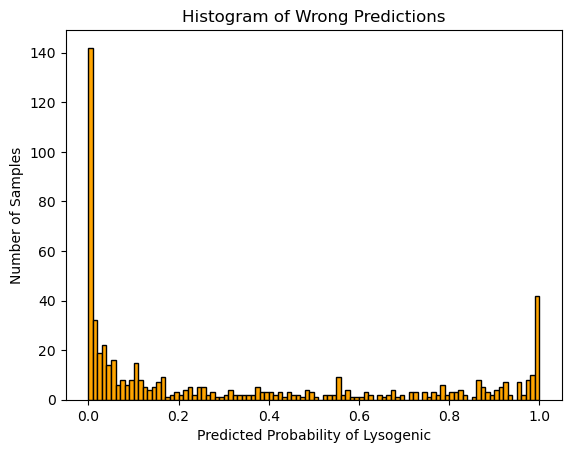

In [15]:
# np.histogram(pred_y_values, bins=50)
import matplotlib.pyplot as plt

# plt.hist(pred_y_values, bins='auto')  # arguments are passed to np.histogram
plt.hist(wrong_results['prob_lysogenic'], bins=100, color='orange', edgecolor='black')
plt.title("Histogram of Wrong Predictions")
plt.xlabel("Predicted Probability of Lysogenic")
plt.ylabel("Number of Samples")
plt.show()

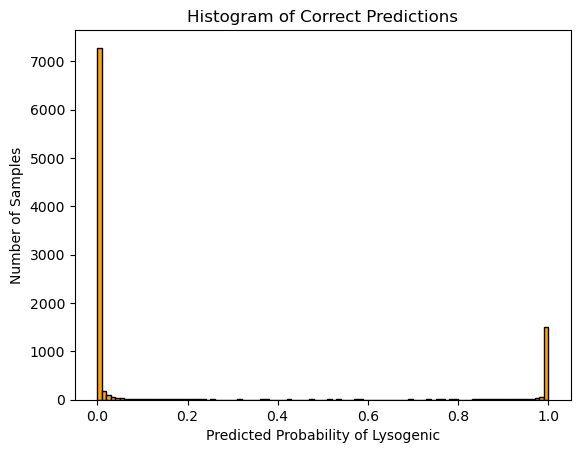

In [16]:
import matplotlib.pyplot as plt

# plt.hist(pred_y_values, bins='auto')  # arguments are passed to np.histogram
plt.hist(all_results.loc[all_results['true_label'] == all_results['predicted_label']]['prob_lysogenic'], bins=100, color='orange', edgecolor='black')
plt.title("Histogram of Correct Predictions")
plt.xlabel("Predicted Probability of Lysogenic")
plt.ylabel("Number of Samples")
plt.show()

# Clustering to indentify significant groups from which we can retrieve meaningfull information

In [17]:
from sklearn.metrics.pairwise import cosine_distances

X_norm = normalizer.transform(df.values)
cos_dist = cosine_distances(X_norm)

cos_dist_df = pd.DataFrame(
    cos_dist,
    index=df.index,
    columns=df.index
)


In [18]:
df_meta = cos_dist_df.copy()

df_meta["lifecycle"] = df_meta.index.map(lifecycle_map)

# Optional sanity check
df_meta["lifecycle"].value_counts(dropna=False)

lifecycle
lytic        8142
lysogenic    2285
Name: count, dtype: int64

In [19]:
from scipy.cluster.hierarchy import linkage, fcluster

Z = linkage(df.values, method="average", metric="cosine")

# choose number of macro clusters
labels = fcluster(Z, t=8, criterion="maxclust")


In [20]:
# Assign cluster labels directly to df_meta
# Since df_meta has the same row order as the df used for clustering,
# we can simply assign the array.
df_meta["cluster"] = labels

# Verify the column was added
print(df_meta[["lifecycle", "cluster"]].head())

          lifecycle  cluster
NC_012663     lytic        1
NC_012663     lytic        1
NC_012663     lytic        1
NC_012663     lytic        1
NC_025467     lytic        1


In [21]:
set(df.columns) == set(df_meta.index)

False

In [22]:
# Cosine similarity matrix
df_meta.head()

,NC_012663,NC_012663,NC_012663,NC_012663,NC_025467,AJ298298,AJ298298,AJ298298,NC_025436,NC_025436,...,NC_015253,NC_015253,NC_015253,NC_015253,NC_015253,AY954955,AY954955,AY954955,lifecycle,cluster
NC_012663,0.000000,0.001114,0.002569,0.006707,0.009678,0.202093,0.205894,0.179220,0.032701,0.020150,...,0.021094,0.018203,0.015187,0.021769,0.023918,0.084850,0.100778,0.254112,lytic,1
NC_012663,0.001114,0.000000,0.000969,0.009017,0.011599,0.197586,0.200234,0.172149,0.037742,0.024126,...,0.016947,0.014497,0.012577,0.021227,0.025376,0.083494,0.100073,0.252402,lytic,1
NC_012663,0.002569,0.000969,0.000000,0.006450,0.011833,0.200146,0.201969,0.173575,0.035374,0.021385,...,0.014734,0.014402,0.011311,0.017344,0.022076,0.090264,0.106086,0.258503,lytic,1
NC_012663,0.006707,0.009017,0.006450,0.000000,0.010581,0.220020,0.223367,0.197653,0.024871,0.010614,...,0.023394,0.026489,0.019218,0.015681,0.015296,0.109510,0.122110,0.278737,lytic,1
NC_025467,0.009678,0.011599,0.011833,0.010581,0.000000,0.212622,0.218694,0.194199,0.015088,0.011078,...,0.041896,0.039076,0.035089,0.041133,0.042787,0.095430,0.110539,0.271167,lytic,1


In [23]:
cluster_counts = (
    df_meta
    .groupby(["cluster", "lifecycle"])
    .size()
    .unstack(fill_value=0)
)

cluster_counts

lifecycle,lysogenic,lytic
cluster,,
1,587,4959
2,13,51
3,15,22
4,844,2520
5,0,1
6,350,54
7,476,534
8,0,1


In [24]:
cluster_fractions = cluster_counts.div(cluster_counts.sum(axis=1), axis=0)

cluster_fractions

lifecycle,lysogenic,lytic
cluster,,
1,0.105842,0.894158
2,0.203125,0.796875
3,0.405405,0.594595
4,0.250892,0.749108
5,0.000000,1.000000
6,0.866337,0.133663
7,0.471287,0.528713
8,0.000000,1.000000


In [25]:
from scipy.stats import fisher_exact

results = []

total = df_meta["lifecycle"].value_counts()

for cluster_id in cluster_counts.index:
    a = cluster_counts.loc[cluster_id].get("lysogenic", 0)
    b = cluster_counts.loc[cluster_id].get("lytic", 0)
    c = total["lysogenic"] - a
    d = total["lytic"] - b

    _, pval = fisher_exact([[a, b], [c, d]], alternative="greater")

    results.append((cluster_id, pval))

enrichment_df = pd.DataFrame(
    results,
    columns=["cluster", "lysogenic_enrichment_p"]
).set_index("cluster")

enrichment_df


,lysogenic_enrichment_p
cluster,
1,1.000000e+00
2,6.697536e-01
3,8.150863e-03
4,4.615324e-08
5,1.000000e+00
6,2.231605e-178
7,4.972762e-79
8,1.000000e+00


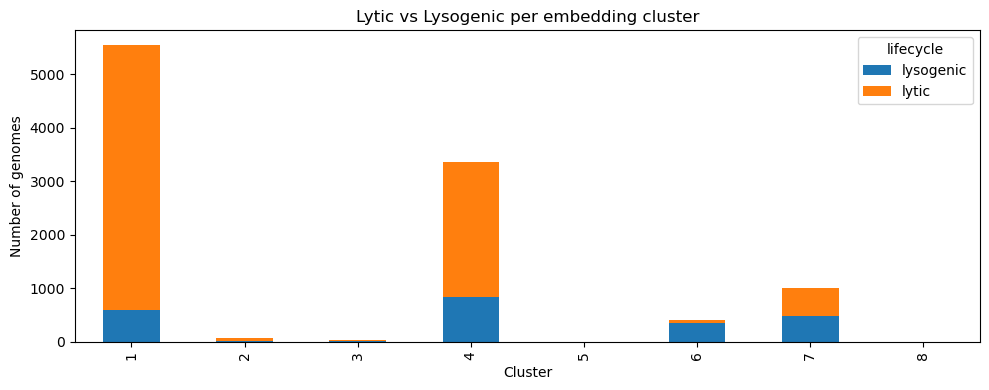

In [26]:
import seaborn as sns
import matplotlib.pyplot as plt

cluster_counts.plot(
    kind="bar",
    stacked=True,
    figsize=(10, 4)
)

plt.ylabel("Number of genomes")
plt.xlabel("Cluster")
plt.title("Lytic vs Lysogenic per embedding cluster")
plt.tight_layout()


### UMAP visualization (structure + lifecycle separation)

In [27]:
import umap
import matplotlib.pyplot as plt
import seaborn as sns

reducer = umap.UMAP(
    n_neighbors=15,
    min_dist=0.1,
    metric="cosine"
)

X_umap = reducer.fit_transform(cos_dist_df.values)

umap_df = pd.DataFrame(
    X_umap,
    columns=["UMAP1", "UMAP2"],
    index=cos_dist_df.index
)

umap_df = umap_df.join(df_meta[["cluster", "lifecycle"]])

/Users/francescostella/anaconda3/envs/thesis/lib/python3.12/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


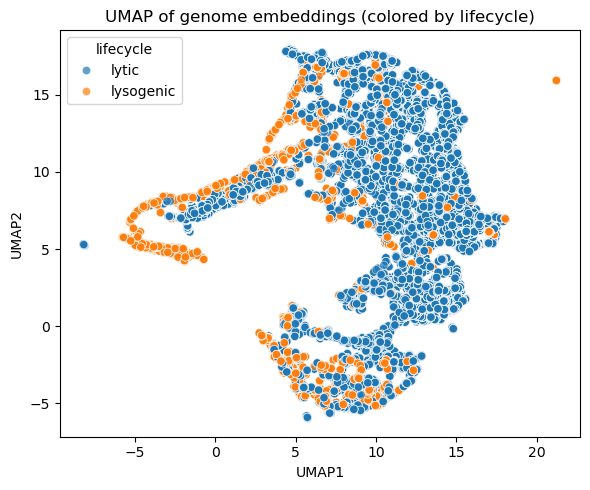

In [28]:
plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="lifecycle",
    alpha=0.7
)
plt.title("UMAP of genome embeddings (colored by lifecycle)")
plt.tight_layout()

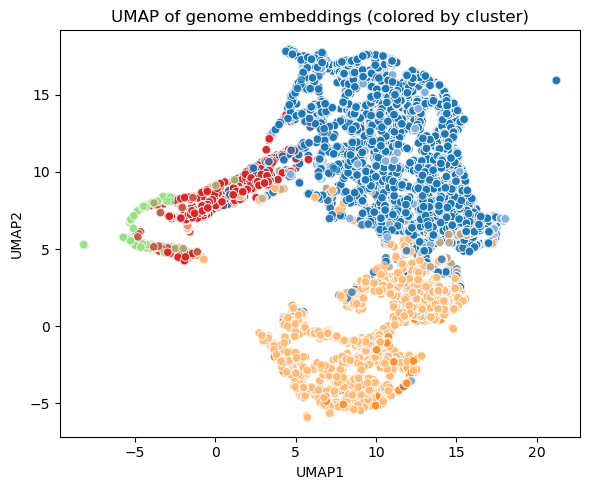

In [29]:
plt.figure(figsize=(6, 5))
sns.scatterplot(
    data=umap_df,
    x="UMAP1",
    y="UMAP2",
    hue="cluster",
    palette="tab20",
    legend=False,
    alpha=0.7
)
plt.title("UMAP of genome embeddings (colored by cluster)")
plt.tight_layout()


### Cluster centroids (representative genomes)

In [30]:
import numpy as np

centroids = (
    cos_dist_df
    .groupby(df_meta["cluster"])
    .mean()
)


In [31]:
from sklearn.metrics.pairwise import cosine_distances

representatives = {}

for cluster_id, centroid in centroids.iterrows():
    distances = cosine_distances(
        cos_dist_df.values,
        centroid.values.reshape(1, -1)
    ).ravel()

    closest_idx = distances.argmin()
    representatives[cluster_id] = cos_dist_df.index[closest_idx]

rep_df = pd.DataFrame.from_dict(
    representatives,
    orient="index",
    columns=["representative_accession"]
)

rep_df


,representative_accession
1,NC_028758
2,NC_025420
3,NC_042314
4,NC_005131
5,NC_002643
6,AF503408
7,NC_021530
8,NC_042009


# Lifecycle composition table

Highlight lysogenic-lytic genomes distribution inside clusters

In [32]:
cluster_counts = (
    df_meta
    .groupby(["cluster", "lifecycle"])
    .size()
    .unstack(fill_value=0)
)
print(cluster_counts)

lifecycle  lysogenic  lytic
cluster                    
1                587   4959
2                 13     51
3                 15     22
4                844   2520
5                  0      1
6                350     54
7                476    534
8                  0      1


In [33]:
cluster_fractions = cluster_counts.div(
    cluster_counts.sum(axis=1),
    axis=0
)
print(cluster_fractions)

lifecycle  lysogenic     lytic
cluster                       
1           0.105842  0.894158
2           0.203125  0.796875
3           0.405405  0.594595
4           0.250892  0.749108
5           0.000000  1.000000
6           0.866337  0.133663
7           0.471287  0.528713
8           0.000000  1.000000


Compute Fisher's exact test to check significance of the distributions

In [34]:
from scipy.stats import fisher_exact

total_counts = df_meta["lifecycle"].value_counts()

enrichment = []

for cluster_id, row in cluster_counts.iterrows():
    a = row.get("lysogenic", 0)
    b = row.get("lytic", 0)
    c = total_counts["lysogenic"] - a
    d = total_counts["lytic"] - b

    oddsratio, pval = fisher_exact(
        [[a, b], [c, d]],
        alternative="greater"
    )

    enrichment.append({
        "cluster": cluster_id,
        "lysogenic_fraction": a / (a + b),
        "odds_ratio": oddsratio,
        "p_value": pval
    })

enrichment_df = pd.DataFrame(enrichment).set_index("cluster")
enrichment_df.sort_values("p_value")


,lysogenic_fraction,odds_ratio,p_value
cluster,,,
6,0.866337,27.091588,2.231605e-178
7,0.471287,3.748846,4.972762e-79
4,0.250892,1.306679,4.615324e-08
3,0.405405,2.438927,8.150863e-03
2,0.203125,0.907752,6.697536e-01
1,0.105842,0.221893,1.000000e+00
5,0.000000,0.000000,1.000000e+00
8,0.000000,0.000000,1.000000e+00


### Check other things

In [54]:
# Add start and end columns
df["start"] = starts_list
df["end"] = ends_list

### Genomes Feature Extraction

In [37]:
from Bio import SeqIO

In [111]:
def gbk_to_feature_df(gbk_path):
    record = SeqIO.read(gbk_path, "genbank")
    rows = []
    genome_length = len(record.seq)
    # print("Accession", record.id)
    for feature in record.features:
        # if feature.type in {"CDS", "gene"}:
        if feature.type in {"CDS"}:
            rows.append({
                "accession": record.id.strip().split('.')[0],
                "type": feature.type,
                "start": int(feature.location.start),
                "end": int(feature.location.end),
                "strand": feature.location.strand,
                "gene":( 
                    feature.qualifiers.get("gene")[0] 
                    if feature.qualifiers.get("gene", [None])[0] is not None
                    else feature.qualifiers.get("locus_tag", [None])[0]
                ),
                "product": feature.qualifiers.get("product", [None])[0],
            })

    # If no CDS or gene are found in the gbk description, then just add empty row
    if len(rows) == 0:
        rows.append({
                "accession": record.id,
                "type": None,
                "start": None,
                "end": None,
                "strand": None,
                "gene": None,
                "product": None,
            })
    
    return [pd.DataFrame(rows), genome_length]

In [ ]:
from pathlib import Path

gbk_folder_path = '../data/data_gbk'
gbk_dir = Path(gbk_folder_path)
feature_tables = {} # Contains features of each CDS
acc_length = {}     # Contains length of each genome

for gbk in gbk_dir.glob("*.gbk"):
    df_feat, genome_length = gbk_to_feature_df(gbk)
    # print(df_feat.head())
    feature_tables[df_feat.accession.iloc[0]] = df_feat
    acc_length[df_feat.accession.iloc[0]] = genome_length
    
print(f"Processed {len(feature_tables)} GBK files.")

Processed 2177 GBK files.


In [113]:
# Remove entries from feature_tables that are not in index
print(set([acc.strip().split('.')[0] for acc in feature_tables.keys()]) - set(df.index.unique()))

extra_acc = list((set([acc.strip().split('.')[0] for acc in feature_tables.keys()]) - set(df.index.unique())))
for acc in extra_acc:
    feature_tables.pop(acc)
    
print(set([acc.strip().split('.')[0] for acc in feature_tables.keys()]) - set(df.index.unique()))

{'NC_028959'}
set()


In [114]:
# Retrieve all genes and their counts from feature tables
genes = {}

for acc, feat_df in feature_tables.items():
    gene = feat_df['gene'].to_list()
    # print(gene)
    for g in gene:
        g = g.strip().lower() if g is not None else 'unknown_gene'
        # g = g.strip() if g is not None else 'unknown_gene'
        if g not in genes.keys():
            genes[g] = 1
        else:
            genes[g] += 1

print(len(genes))


# Filter and Sort
sorted_items = sorted(
    [item for item in genes.items() if not item[0].isdigit()],  # Filter: Keep if key is NOT a digit
    key=lambda item: item[1],                                   # Sort Key: Sort by the value (count)
    reverse=True                                                # Order: Decreasing
)

# Create the dictionary (optional, or just use the list)
most_represented_genes = dict(sorted_items)

# Print the top 100
print(list(most_represented_genes.items())[:100])

177576
[('unknown_gene', 14349), ('int', 104), ('nrdb', 97), ('nrda', 92), ('uvsw', 83), ('rega', 78), ('td', 76), ('nrdc', 71), ('uvsx', 69), ('uvsy', 69), ('riib', 64), ('riia', 62), ('frd', 62), ('e', 61), ('nrdd', 60), ('cd', 58), ('rnh', 57), ('pset', 56), ('dda', 55), ('dexa', 54), ('nrdh', 54), ('rnla', 54), ('dam', 53), ('wac', 53), ('dsba', 53), ('denv', 52), ('inh', 52), ('t', 52), ('tk', 51), ('ci', 50), ('alt', 50), ('rpba', 47), ('asia', 45), ('dena', 44), ('nrdg', 43), ('q', 42), ('ndd', 42), ('hoc', 42), ('rnlb', 41), ('terl', 41), ('srd', 40), ('ri', 39), ('cro', 38), ('mota', 38), ('o', 38), ('p', 38), ('orf10', 38), ('gp47', 37), ('n', 37), ('orf16', 37), ('orf18', 37), ('orf19', 37), ('regb', 36), ('alc', 36), ('orf12', 36), ('orf13', 36), ('orf14', 36), ('orf15', 36), ('orf17', 36), ('gp17', 35), ('orf11', 35), ('j', 35), ('gp19', 34), ('gp23', 34), ('nude', 34), ('riii', 34), ('hol', 34), ('orf23', 34), ('d', 34), ('hli03', 34), ('gp15', 33), ('gp26', 33), ('gp32',

In [115]:
# Retrieve all products and their counts from feature tables
def retrive_products(feature_tables, lifecycle_map, lifecycle):
    products = {}

    for acc, feat_df in feature_tables.items():
        product = feat_df['product'].to_list()
        if lifecycle_map.get(acc) != lifecycle:   # If '!=' we retain only lysogenic
            continue
        for p in product:
            p = p.strip().lower() if p is not None else 'unknown_product'
            if p not in products.keys():
                products[p] = 1
            else:
                products[p] += 1

    print(len(products))

    # Filter and Sort
    sorted_items = sorted(
        [item for item in products.items()],
        key=lambda item: item[1],                                   
        reverse=True                                                
    )
    
    return dict(sorted_items)

In [117]:
print(retrive_products(feature_tables, lifecycle_map, "lytic"))
# integrase
# print elements with 'integrase' in the name
lytic_products = retrive_products(feature_tables, lifecycle_map, "lytic")
for product, count in lytic_products.items():
    if 'integrase' in product:
    # if 'int' in product:
        print(f"{product}: {count}")
        
lysogenic_products = retrive_products(feature_tables, lifecycle_map, "lysogenic")
print(lysogenic_products)

7369
{'hypothetical protein': 101892, 'virion structural protein': 2661, 'tail protein': 1382, 'tail fiber protein': 1382, 'hnh endonuclease': 1365, 'baseplate wedge subunit': 1245, 'terminase large subunit': 1142, 'dna polymerase': 1079, 'endolysin': 1014, 'major head protein': 986, 'portal protein': 934, 'exonuclease': 856, 'membrane protein': 831, 'holin': 829, 'dna helicase': 795, 'minor tail protein': 751, 'terminase small subunit': 740, 'tail length tape measure protein': 721, 'rz-like spanin': 703, 'dna primase': 688, 'tail assembly chaperone': 636, 'head maturation protease': 589, 'endonuclease': 564, 'head scaffolding protein': 543, 'thymidylate synthase': 521, 'dna methyltransferase': 480, 'transcriptional regulator': 471, 'tail sheath': 451, 'internal virion protein': 419, 'single strand dna binding protein': 418, 'dna binding protein': 401, 'homing endonuclease': 387, 'structural protein': 373, 'baseplate hub': 369, 'predicted orf': 363, 'major tail protein': 348, 'rna liga

In [118]:
# Now tokenize all products and then apply set difference to find unique tokens
import re

unique_tokens = set()

# Retrieve Lytic Products
most_represented_products_lytic = retrive_products(feature_tables, lifecycle_map, "lytic")
# Split by space OR forward slash
# re.split(r'[ /]+', item) splits on one or more spaces or slashes
lytic_tokens_list = [re.split(r'[ /]+', item.strip()) for item in most_represented_products_lytic.keys()]

# Flatten the list of lists into a single set of tokens
lytic_tokens = {token for sublist in lytic_tokens_list for token in sublist if token}

print(list(lytic_tokens)[:10])

# Retrieve Lysogenic Products
most_represented_products_lysogenic = retrive_products(feature_tables, lifecycle_map, "lysogenic")
lysogenic_tokens_list = [re.split(r'[ /-_]+', item.strip()) for item in most_represented_products_lysogenic.keys()]

# Flatten and create set
lysogenic_tokens = {token for sublist in lysogenic_tokens_list for token in sublist if token}

# Calculate Difference
unique_tokens = lysogenic_tokens - lytic_tokens

print(f'Unique tokens in lysogenic products are {len(unique_tokens)}')
print(unique_tokens)

7369
['zn-ribbon', 'middle', 'gp583', 'gp020', 'amp-binding', 'vr7orf033w', 'gmp', 'purm', 'gp27.7', 'gp248']
3542
Unique tokens in lysogenic products are 815
{'dgr', 'rinmiddle', 'corrinoid', 'trbp', 'editing', 'laci-like', 'ea', 'glycerol-', 'ycsf', 'aph(', 'hp', 'bor-like', 'anchored', 'degv', 'sce', 'fdc', 'suni', 'adenosyltransferase', 'delta', 'coi', 'hkas', 'spea', 'hypa', 'pare', 'phosphodiester', 'tai', 'yp', 'colonic', 'betaine', '-pyruvoyl-tetrahydropterin', 'antb', 'iram', 'mazf', 'leishmanolysin-like', 'mokw-like', 'pesticin', 'brush', 'heicase', 'htpa', 'orfs', 'replicase', 'acetylase', 'pid', 'ricin-type', 'cellulase', 'chromosomes)', '-n-acetylglucosaminyltransferase', 'gtra', 'exotoxin', 'pmgl', 'ciii', 'ydei', 'tp', 'lpd', 'pin-like', 'yafo', 'marmp', 'enterobacter', 'yeef', 'autoinducer', 'bplb', 'copg-like', 'nuclease-like', 'pua', 'branch', 'botulinum', 'retron', '-binding', 'streptococcal', 'tumb', 'holin-like', 'upl', 'pemk', 'hit', 'cyanothece', 'nun', 'group-sp

In [119]:
# Create the filtered dictionary
filtered_lysogenic_dict = {
    product: count 
    for product, count in most_represented_products_lysogenic.items()
    if not set(re.split(r'[ /]+', product.strip())).isdisjoint(unique_tokens)
}

print(f"Original count: {len(most_represented_products_lysogenic)}")
print(f"Filtered count: {len(filtered_lysogenic_dict)}")
print(list(filtered_lysogenic_dict.items()))

Original count: 3542
Filtered count: 764
[('panton-valentine leukocicin', 90), ('metallo-protease', 85), ('na/k atpase', 46), ('ciii anti-termination', 45), ('antitermination protein', 41), ('nine family protein', 38), ('anti-termination protein n-like', 33), ('abc2 anti-recbcd', 28), ('bppu family baseplate upper protein', 26), ('protein ninf', 26), ('reca filament binding protein dini', 22), ('shiga toxin subunit a', 20), ('rha-like transcriptional regulator', 19), ('shiga toxin subunit b', 19), ('umud-like protein', 18), ('cox-like excisionase and repressor', 18), ('sasa family carbohydrate esterase', 17), ('antirepressor kilac domain-containing protein', 16), ('gtrb glycosyltransferase for o-antigen conversion', 15), ('gtra-like o-antigen conversion', 15), ('bor-like outer membrane protein', 15), ('transcriptional regulator alpa family protein', 15), ("putative dna-directed rna polymerase, beta' subunit/160 kd subunit", 15), ('nucleoid-associated protein yejk', 15), ('mokw-like hos

### Statistical Enrichment of "Marker" Keywords

Lysogenic cycles are biologically defined by specific mechanisms (integration into the host, maintenance of the prophage state). Lytic cycles focus on replication and lysis. You can quantify the presence of specific keywords associated with these processes.

Keywords to check:

Lysogenic markers: integrase, excisionase, repressor, parA, parB (partitioning), transposase.

Lytic/Structural markers: capsid, tail, fiber, polymerase, helicase, lysis, holin.

The Strategy: Calculate the prevalence of each keyword in the Lytic group vs. the Lysogenic group. (e.g., "Integrase appears in 95% of Lysogenic genomes but only 2% of Lytic genomes").

In [120]:
# Define your keywords of interest
keywords = [
    "integrase", "excisionase", "repressor", "transposase", "int", "ciii", "cii", "ci", # Lysogeny associated
    "capsid", "tail", "polymerase", "helicase", "holin", "lysin", "virion", "cro", "n protein", # Structural/Lytic associated
    "terminase", "portal", "scaffold", "major capsid protein", "minor capsid protein", "mor"
]

# Initialize counters
# Structure: {'integrase': {'lytic': 0, 'lysogenic': 0}, ...}
keyword_counts = {k: {'lytic': 0, 'lysogenic': 0} for k in keywords}
genome_counts = {'lytic': 0, 'lysogenic': 0}

# Iterate through all genomes in your feature_tables
# Note: feature_tables is the dictionary you loaded containing gene product info
for accession, products_df in feature_tables.items():
    # Get the label (default to lytic if missing)
    label = lifecycle_map.get(accession, "lytic")
    genome_counts[label] += 1
    
    # Convert all products to a single lowercase string for searching
    # (Handling cases where products_df might be empty or missing columns)
    if 'product' in products_df.columns:
        all_products_text = " ".join(products_df['product'].dropna().astype(str)).lower()
        
        for k in keywords:
            if k in all_products_text:
                keyword_counts[k][label] += 1

# Calculate Frequency and Print
results = []
for k in keywords:
    lytic_pct = (keyword_counts[k]['lytic'] / genome_counts['lytic']) * 100
    lyso_pct = (keyword_counts[k]['lysogenic'] / genome_counts['lysogenic']) * 100
    diff = lyso_pct - lytic_pct
    results.append({
        "Keyword": k,
        "Lytic_Freq (%)": round(lytic_pct, 1),
        "Lysogenic_Freq (%)": round(lyso_pct, 1),
        "Difference (Lyso - Lytic)": round(diff, 1)
    })

results_df = pd.DataFrame(results).sort_values("Difference (Lyso - Lytic)", ascending=False)
print(results_df)

                 Keyword  Lytic_Freq (%)  Lysogenic_Freq (%)  \
0              integrase             0.8                80.0   
4                    int            21.6                81.0   
2              repressor            21.2                71.8   
7                     ci            43.5                70.6   
18                portal            63.1                83.6   
1            excisionase             1.6                22.0   
12                 holin            53.5                69.3   
6                    cii             0.1                14.8   
20  major capsid protein            15.3                27.1   
15                   cro             4.3                15.0   
5                   ciii             0.0                 7.6   
3            transposase             6.2                13.6   
13                 lysin            67.6                71.5   
8                 capsid            29.4                31.5   
16             n protein            56.7

# Analyze the "Misclassified" Genomes

Your machine learning model achieved high accuracy (~94%), but it made mistakes. Analyzing the biology of the mistakes is often more revealing than the successes.

The Strategy: Look at the False Positives (Lytic genomes predicted as Lysogenic). Do they contain "Integrases"? If so, your model might actually be correct, and the ground truth label might be wrong (or the phage is "temperate-like" but labeled lytic).

In [121]:
# Identify False Positives (Labeled Lytic, Predicted Lysogenic)
fp_accessions = all_results[
    (all_results['true_label'] == 'lytic') & 
    (all_results['predicted_label'] == 'lysogenic')
]['accession'].values

print(f"Analyzing {len(fp_accessions)} False Positives...")

# Check for 'Integrase' in these specific genomes
fp_with_integrase = 0
for acc in fp_accessions:
    if acc in feature_tables:
        prod_text = " ".join(feature_tables[acc]['product'].dropna().astype(str)).lower()
        if "integrase" in prod_text:
            fp_with_integrase += 1

print(f"Out of {len(fp_accessions)} Lytic genomes predicted as Lysogenic, {fp_with_integrase} contain an 'integrase'.")
print("These might be mislabeled in the database or are temperate phages acting lytically.")

Analyzing 252 False Positives...
Out of 252 Lytic genomes predicted as Lysogenic, 17 contain an 'integrase'.
These might be mislabeled in the database or are temperate phages acting lytically.


# Cluster Profiling (Using your Clusters)

You grouped genomes into clusters (0-9). Some clusters are heavily Lysogenic (e.g., Cluster 0), and others are Lytic (e.g., Cluster 1).

The Strategy: Extract the "Top 5 Words" for Cluster 0 vs Cluster 1. This tells you biologically what those clusters represent without guessing.

In [122]:
from collections import Counter
import re

def get_cluster_top_words(target_cluster_id):
    # Get all accessions in this cluster
    cluster_accessions = df_meta[df_meta['cluster'] == target_cluster_id].index
    
    word_counter = Counter()
    
    for acc in cluster_accessions:
        if acc in feature_tables:
            # Get list of products
            products = feature_tables[acc]['product'].dropna().astype(str).tolist()
            for prod in products:
                # Basic tokenization: split by space, remove common stop words if needed
                words = re.findall(r'\w+', prod.lower())
                # Filter out generic words
                words = [w for w in words if w not in ['hypothetical', 'protein', 'putative', 'phage', 'gp']]
                word_counter.update(words)
                
    return word_counter.most_common(10)

# Compare a Lysogenic-heavy cluster (e.g., 0) with a Lytic-heavy cluster (e.g., 1)
print("Top words in Cluster 6 (Lysogenic-heavy):")
print(get_cluster_top_words(6))

print("\nTop words in Cluster 7 (Lytic-heavy):")
print(get_cluster_top_words(7))

print("\nTop words in Cluster 4 (Lytic-heavy):")
print(get_cluster_top_words(4))

Top words in Cluster 6 (Lysogenic-heavy):
[('tail', 3189), ('like', 2049), ('family', 1483), ('head', 1341), ('transcriptional', 883), ('subunit', 790), ('minor', 734), ('dna', 704), ('anti', 690), ('domain', 668)]

Top words in Cluster 7 (Lytic-heavy):
[('tail', 9288), ('dna', 7100), ('like', 6778), ('subunit', 6701), ('head', 5358), ('baseplate', 4533), ('ii', 3907), ('conserved', 3562), ('endonuclease', 3125), ('oxygenase', 3079)]

Top words in Cluster 4 (Lytic-heavy):
[('tail', 25927), ('dna', 17352), ('virion', 11679), ('structural', 11618), ('like', 11570), ('head', 10850), ('subunit', 10429), ('orf', 8582), ('predicted', 8408), ('polymerase', 7899)]


# Correlation of Products to Their position in the genome

In [253]:
print(type(feature_tables))
print(len(feature_tables.keys())) 
# TARGET_PRODUCT = 'integrase'
# TARGET_PRODUCT = 'terminase'
keywords = [
    "integrase", "excisionase", "repressor", "transposase", "int", "ciii", "cii", "ci", # Lysogeny associated
    # "capsid", "tail", "polymerase", "helicase", "holin", "lysin", "virion", "cro", "n protein", # Structural/Lytic associated
    # "terminase", "portal", "scaffold", "major capsid protein", "minor capsid protein", "mor"
]
acc = []
start = []
end = []

for key in feature_tables.keys():
    # Retrieve all positions of start and end of integrase
    for i in range(len(feature_tables[key])):
        # if (    feature_tables[key]['product'][i] is not None and
        #         TARGET_PRODUCT in set(feature_tables[key]['product'][i].lower().split())):
        if (feature_tables[key]['product'][i] is not None and
            any(prod in keywords for prod in set(feature_tables[key]['product'][i].lower().split()))):
            acc.append(key)
            start.append(feature_tables[key]['start'][i])
            end.append(feature_tables[key]['end'][i])
    
print(len(start))

<class 'dict'>
2176
1941


In [254]:
# print(feature_tables[acc[start.index(max(start))]])

In [255]:
print(acc[start.index(max(start))])
print(start.index(max(start)))
print(end.index(max(end)))
print(max(start))
print(max(end))

NC_023719
960
960
471631
472831


In [256]:
140932 / 16384

8.601806640625

In [257]:
# Take the middle point of the product, divide for the length of the genome and create a distribution
# import time
# pos_ratio = []
# t0 = time.time()
# for i in range(len(start)):
#     mid = (start[i] + end[i]) / 2
#     pos_ratio.append(mid)
    
# t1 = time.time()

# print(f"Time taken: {t1 - t0:.5f} seconds")
import time
# Assuming start and end are converted to numpy arrays
acc_length_arr = np.array([acc_length[key] for key in acc])
starts_arr = np.array(start)
ends_arr = np.array(end)
t0 = time.time()
# Vectorized operation: happens instantly in C
mid_point = (starts_arr + ends_arr) // 2
pos_ratio = mid_point / acc_length_arr
t1 = time.time()
print(len(pos_ratio))
print(f"Time taken: {t1 - t0:.5f} seconds")

1941
Time taken: 0.00287 seconds


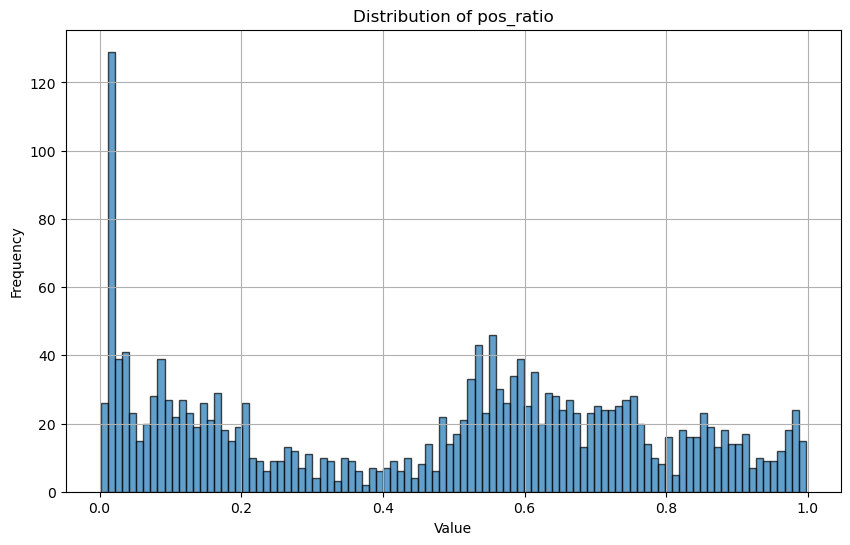

In [258]:
# import numpy as np
# import matplotlib.pyplot as plt

plt.figure(figsize=(10, 6))
plt.hist(pos_ratio, bins=100, edgecolor='k', alpha=0.7)
plt.title('Distribution of pos_ratio')
plt.xlabel('Value')
plt.ylabel('Frequency')
plt.grid(True)
plt.savefig('pos_ratio_distribution.png')